# Feature selection

Which inputs should the models use? Candidates are the variables in the ERA-40 2 PVU files, plus lags and neighbouring longitudes of B. Training winters only.

**Test:** predict tomorrow's B at each longitude from today's B plus one candidate, by linear regression, scored on held-out winters (5-fold `GroupKFold` by winter). The gain in R² over today's B alone shows what each candidate adds. This is supporting evidence; the project's question and domain knowledge come first.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

sys.path.append("..")
from plot_era40 import _valid_time, _reduced_to_full   # also sets up eccodes in the right order
import eccodes as ec
from blocking_index import band_weights, CBL_FIXED

TRAIN_YEARS = range(1957, 1987)        # winter = December of this year to February of the next
LONS = np.arange(0, 360, 5)
VARS = ["pt", "pres", "z", "u", "v", "q", "o3"]
NAMES = dict(pt="theta", pres="pressure", z="geopotential", u="eastward wind", v="northward wind", q="humidity", o3="ozone")

## Candidate indices

Each variable is turned into two daily numbers per longitude, using the same bands as B around the fixed central latitude: north band minus south band, and the average of the two. Slow step (reads 90 files); cached in `data/derived/`, which git ignores.

In [2]:
CACHE = "../data/derived/train_djf_candidate_indices.npz"

def read_daily(path):
    """{variable: (days, lat, lon)} daily means from one monthly file, plus lats, lons, dates."""
    sums, lats = {}, None
    with open(path, "rb") as f:
        while (gid := ec.codes_grib_new_from_file(f)) is not None:
            try:
                name = ec.codes_get(gid, "shortName")
                arr = _reduced_to_full(ec.codes_get_values(gid), ec.codes_get_array(gid, "pl").astype(int))
                if lats is None:
                    lats = ec.codes_get_array(gid, "distinctLatitudes")
                    lons = np.arange(arr.shape[1]) * 360.0 / arr.shape[1]
                day = _valid_time(gid).date()
                sums.setdefault(name, {}).setdefault(day, []).append(arr)
            finally:
                ec.codes_release(gid)
    dates = sorted(sums["pt"])
    return {v: np.array([np.mean(sums[v][d], axis=0) for d in dates]) for v in VARS}, lats, lons, dates

def band_matrices(lats, lons):
    """(72, nlat * nlon) weights for the north and south band means at each target longitude."""
    north, south = [np.zeros((72, lats.size * lons.size)) for _ in range(2)]
    for j, (lon, c) in enumerate(zip(LONS, CBL_FIXED)):
        box = np.abs((lons - lon + 180) % 360 - 180) <= 2.5
        box = box / box.sum()
        north[j] = np.outer(band_weights(lats, c, c + 15), box).ravel()
        south[j] = np.outer(band_weights(lats, c - 15, c), box).ravel()
    return north, south

if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True)
    ns, avg, dates = z["ns"].item(), z["avg"].item(), pd.DatetimeIndex(z["dates"])
else:
    ns, avg, dates, W = {v: [] for v in VARS}, {v: [] for v in VARS}, [], None
    for y in TRAIN_YEARS:
        for ym in (f"{y}12", f"{y+1}01", f"{y+1}02"):
            fields, lats, lons, ds = read_daily(f"../data/e4oper.an.pv.{ym}")
            if W is None:
                W = band_matrices(lats, lons)
            for v in VARS:
                flat = fields[v].reshape(len(ds), -1)
                n, s = flat @ W[0].T, flat @ W[1].T
                ns[v].append(n - s)
                avg[v].append((n + s) / 2)
            dates += ds
        print(y, "done", flush=True)
    ns = {v: np.concatenate(x) for v, x in ns.items()}
    avg = {v: np.concatenate(x) for v, x in avg.items()}
    dates = pd.DatetimeIndex(dates)
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    np.savez(CACHE, ns=ns, avg=avg, dates=dates.values)
print({k: v.shape for k, v in ns.items()}, dates[0].date(), dates[-1].date())

{'pt': (2707, 72), 'pres': (2707, 72), 'z': (2707, 72), 'u': (2707, 72), 'v': (2707, 72), 'q': (2707, 72), 'o3': (2707, 72)} 1957-12-01 1987-02-28


## Build the regression table

Target: B tomorrow. Rows need yesterday, today and tomorrow in one winter, so every candidate is scored on the same days. Only today's and earlier values are used, so nothing from the target day leaks in. LIB, SB and SBE are computed from B, so they are targets and not candidates.

In [3]:
B = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_TH08.parquet").rename(columns=int).loc[dates].to_numpy()
winter = np.array([d.year if d.month == 12 else d.year - 1 for d in dates])

same = (winter[:-2] == winter[1:-1]) & (winter[1:-1] == winter[2:])
rows = np.flatnonzero(same) + 1                        # today's index
groups = winter[rows]
y = B[rows + 1]                                        # tomorrow
base = B[rows]                                         # today

candidates = {f"{NAMES[v]}: north minus south": ns[v][rows] for v in VARS}
candidates.update({f"{NAMES[v]}: band average": avg[v][rows] for v in VARS})
candidates["B yesterday (lag 2)"] = B[rows - 1]
for shift, label in [(1, "west"), (-1, "east")]:
    for steps in (1, 2, 3):
        candidates[f"B today, {5 * steps}° {label}"] = np.roll(B[rows], shift * steps, axis=1)

In [4]:
def cv_r2(features):
    """Out-of-sample R² at each longitude; features is a list of (rows, 72) arrays."""
    scores = np.zeros((5, 72))
    for fold, (tr, te) in enumerate(GroupKFold(5).split(y, groups=groups)):
        for j in range(72):
            A = np.column_stack([f[:, j] for f in features])
            A = (A - A[tr].mean(0)) / A[tr].std(0)   # variables differ in scale by 12 orders of magnitude; scaled on the training folds
            pred = LinearRegression().fit(A[tr], y[tr, j]).predict(A[te])
            scores[fold, j] = 1 - ((y[te, j] - pred) ** 2).sum() / ((y[te, j] - y[tr, j].mean()) ** 2).sum()
    return scores

base_scores = cv_r2([base])
table = []
for name, f in candidates.items():
    gain = cv_r2([base, f]) - base_scores
    same_day = np.mean([abs(np.corrcoef(f[:, j], base[:, j])[0, 1]) for j in range(72)])
    table.append(dict(candidate=name, median_r2_gain=np.median(gain.mean(0)), max_r2_gain=gain.mean(0).max(),
                      worst_fold_median_gain=np.median(gain, axis=1).min(), mean_abs_corr_with_B_today=same_day))
evidence = pd.DataFrame(table).sort_values("median_r2_gain", ascending=False).reset_index(drop=True)
print(f"today's B alone: out-of-sample R² median {np.median(base_scores.mean(0)):.3f}, range {base_scores.mean(0).min():.3f} to {base_scores.mean(0).max():.3f}")
print(evidence.round(4).to_string())

today's B alone: out-of-sample R² median 0.426, range 0.355 to 0.541
                            candidate  median_r2_gain  max_r2_gain  worst_fold_median_gain  mean_abs_corr_with_B_today
0                   B today, 10° west          0.1385       0.1769                  0.1165                      0.6950
1                   B today, 15° west          0.1252       0.1702                  0.1047                      0.4792
2                    B today, 5° west          0.1076       0.1482                  0.0888                      0.9015
3   northward wind: north minus south          0.0452       0.0848                  0.0395                      0.0836
4         eastward wind: band average          0.0293       0.0553                  0.0282                      0.7572
5                    B today, 5° east          0.0222       0.0453                  0.0164                      0.9015
6     geopotential: north minus south          0.0104       0.0425                  0.0092        

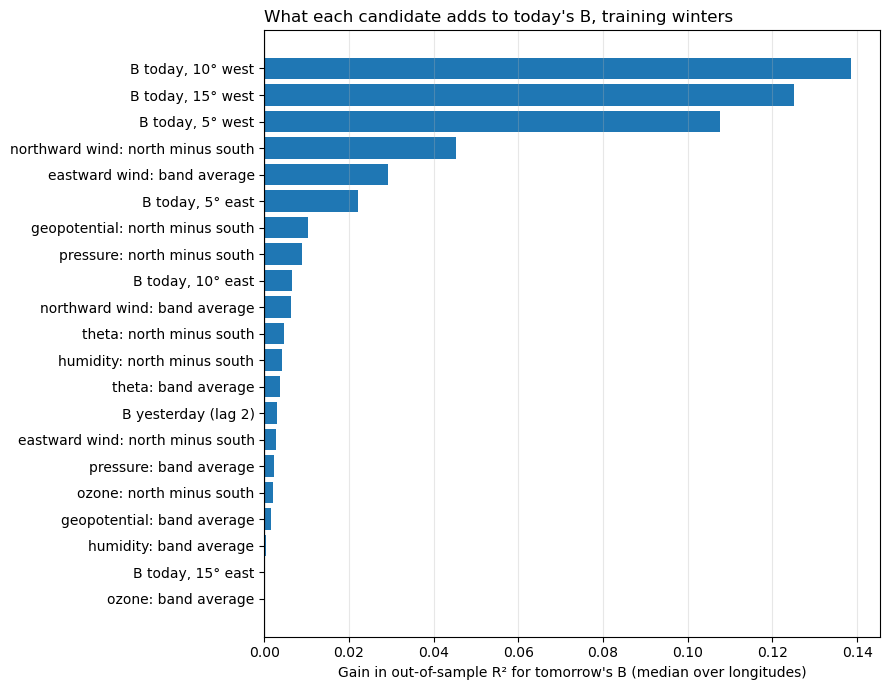

In [5]:
show = evidence.sort_values("median_r2_gain")
plt.figure(figsize=(9, 7))
plt.barh(show.candidate, show.median_r2_gain, color="tab:blue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Gain in out-of-sample R² for tomorrow's B (median over longitudes)")
plt.title("What each candidate adds to today's B, training winters", loc="left")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/eda/ERA40_feature_r2_gain_train.png", dpi=120)
plt.show()

## Decisions

The project asks how far theta on 2 PVU alone can explain blocking, so scope decides first and the evidence above second. Saved to `results/feature_selection.csv`.

In [6]:
USED = "used in models"
SCOPE = "not used: outside scope"
UNUSED = "not used: model limitation"
DROP = "dropped"
decisions = {
    "theta: north minus south": (USED, "Basis of B, which takes the maximum of this over three central latitudes"),
    "theta: band average": (DROP, "Little gain; models work with theta anomalies directly"),
    "B today, 5° west": (UNUSED, "Strong signal. Current models couple longitudes symmetrically, so they cannot use its direction"),
    "B today, 10° west": (UNUSED, "Largest gain. Current models couple longitudes symmetrically, so they cannot use its direction"),
    "B today, 15° west": (UNUSED, "Strong signal. Current models couple longitudes symmetrically, so they cannot use its direction"),
    "B today, 5° east": (DROP, "Much weaker than west; correlated with B through the noise instead"),
    "B today, 10° east": (DROP, "Little gain"),
    "B today, 15° east": (DROP, "No gain"),
    "B yesterday (lag 2)": (DROP, "Little gain beyond today's B; agrees with AR(2) fitting a negative second coefficient"),
    "northward wind: north minus south": (SCOPE, "Largest gain outside B, but would need a wind model too. Possible extension"),
    "northward wind: band average": (SCOPE, "Little typical gain; would need a wind model too"),
    "eastward wind: band average": (SCOPE, "Moderate gain, and correlated with B. Would need a wind model too. Used only to locate the central latitude"),
    "eastward wind: north minus south": (SCOPE, "Little gain; would need a wind model too"),
    "geopotential: north minus south": (DROP, "Redundant with B (correlation 0.88); little gain"),
    "geopotential: band average": (DROP, "Little gain"),
    "pressure: north minus south": (DROP, "Redundant with B (correlation 0.86); little gain"),
    "pressure: band average": (DROP, "Little gain"),
    "humidity: north minus south": (DROP, "Little gain"),
    "humidity: band average": (DROP, "No typical gain"),
    "ozone: north minus south": (DROP, "Little gain"),
    "ozone: band average": (DROP, "No typical gain"),
}
assert set(decisions) == set(evidence.candidate)
result = evidence.assign(decision=evidence.candidate.map(lambda c: decisions[c][0]), reason=evidence.candidate.map(lambda c: decisions[c][1]))
result.round(4).to_csv("../results/feature_selection.csv", index=False)
print(result.decision.value_counts().to_string())
print(result[["candidate", "median_r2_gain", "decision"]].round(4).to_string())

decision
dropped                       13
not used: outside scope        4
not used: model limitation     3
used in models                 1
                            candidate  median_r2_gain                    decision
0                   B today, 10° west          0.1385  not used: model limitation
1                   B today, 15° west          0.1252  not used: model limitation
2                    B today, 5° west          0.1076  not used: model limitation
3   northward wind: north minus south          0.0452     not used: outside scope
4         eastward wind: band average          0.0293     not used: outside scope
5                    B today, 5° east          0.0222                     dropped
6     geopotential: north minus south          0.0104                     dropped
7         pressure: north minus south          0.0090                     dropped
8                   B today, 10° east          0.0066                     dropped
9        northward wind: band average  